# Do NFL Combine Drills Predict Career Value? Decision Trees & Random Forests by Position

**IST 707 Final Project** — Marcus Mann, Jordan Hemley, Brady White, Jake Sciamanna

**Question:** How well do NFL Scouting Combine measurements (height, weight, 40-yard dash, bench press, vertical, broad jump, 3-cone, shuttle) predict the value a player produces over his career?

**Outcome:** `w_av` — Pro Football Reference's *Weighted Career Approximate Value*. Approximate Value (AV) is a single number PFR assigns to every player-season to estimate how much he contributed; `w_av` adds those up across a career, giving extra weight to a player's best seasons.

**Two design choices up front:**
1. **Draft classes 2000–2025, adjusted for career length.** A 2024 draftee hasn't had time to pile up `w_av`, so raw `w_av` would mostly measure *how long ago* someone was drafted. We instead predict each player's **percentile rank in `w_av` among his own draft class** (Part 2b explains why).
2. **Skipped drills are left out, not filled in.** If a player didn't do a drill, we never invent a result for him. Trees only use the players who actually ran a drill when they decide where to split on it (Part 2c).

**Approach** (following the Week 6 decision-tree workflow): single decision tree → `max_depth` sweep → `GridSearchCV` → high-variance demo → random forest, then compare **Combine only / Draft only / Combine + Draft**, overall and **by position**, and finish with a drill-by-drill look using only the players who did each drill.

<table align="left"><td>
<a href="https://colab.research.google.com/github/JSciamanna17/IST-707-Final-Project-JS-JH-BW-MM/blob/main/nfl_combine_wav_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
</td></table>

## Setup

Leaving skipped drills blank (instead of filling them in) requires scikit-learn **1.4 or newer**, which is when its trees and forests learned to accept blank (`NaN`) values. Colab already has a newer version; the first cell checks and upgrades only if needed.

In [1]:
import sklearn
from packaging import version
if version.parse(sklearn.__version__) < version.parse('1.4'):
    !pip install -q -U scikit-learn
    print('Upgraded scikit-learn - restart the runtime (Runtime > Restart session) and run again.')
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     GridSearchCV, KFold)
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42

plt.rc('font', size=13)
plt.rc('axes', labelsize=13, titlesize=13)
plt.rc('legend', fontsize=11)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

## Part 1: Load the Data

The merged file (built in `02_merge_data.R`) joins the combine results to draft picks and career stats. We read it straight from the team GitHub repo.

In [3]:
URL = ('https://raw.githubusercontent.com/JSciamanna17/'
       'IST-707-Final-Project-JS-JH-BW-MM/main/nfl_combine_career_data.csv')
raw = pd.read_csv(URL)
print(raw.shape)
raw.head()

(7437, 53)


,season.x,draft_year,draft_team,draft_round,draft_ovr,pfr_id,cfb_id,player_name,pos,school,...,pass_ints,rush_atts,rush_yards,rush_tds,receptions,rec_yards,rec_tds,def_solo_tackles,def_ints,def_sacks
0,2000,2000.0,New York Jets,1.0,13.0,AbraJo00,NaN,John Abraham,OLB,South Carolina,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,463.0,1.0,133.5
1,2000,2000.0,Seattle Seahawks,1.0,19.0,AlexSh00,shaun-alexander-1,Shaun Alexander,RB,Alabama,...,0.0,2187.0,9453.0,100.0,215.0,1520.0,12.0,NaN,NaN,NaN
2,2000,2000.0,Kansas City Chiefs,6.0,188.0,AlfoDa20,NaN,Darnell Alford,OT,Boston Col.,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
3,2000,2000.0,Carolina Panthers,1.0,23.0,AndeRa21,NaN,Rashard Anderson,CB,Jackson State,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,68.0,1.0,NaN
4,2000,NaN,NaN,NaN,NaN,arianjak01,NaN,Jake Arians,K,Ala-Birmingham,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Part 2: Clean and Prepare

### 2a. Basic cleaning

* **Height** comes in as text like `"6-4"` → convert to inches.
* **Position groups.** The raw `pos` column mixes labels (`OT`, `OG`, `C`, `OL`, `G` are all offensive line, etc.), so we collapse them into 10 groups. Kickers, punters, and long snappers are dropped — combine drills are irrelevant to their jobs.
* **Only drafted players.** `w_av` comes from the draft-pick table, so undrafted players have no value recorded. The models answer: *"among drafted players, do drills predict career value?"*
* **Draft classes 2000–2025.** The 2026 class has no NFL games yet, so it's dropped.
* **No leakage.** *Leakage* means letting the model see information it wouldn't have at prediction time. Career stats (games, starts, Pro Bowls, yards, tackles, `dr_av`, etc.) are outcomes, so they are **excluded** from every model.
* **Draft pick** (`pick_num`, overall selection number) is kept as a separate feature set so we can compare drills against where teams actually drafted the player.

In [4]:
df = raw.copy()

def ht_to_in(h):
    try:
        ft, inch = str(h).split('-')
        return int(ft) * 12 + int(inch)
    except ValueError:
        return np.nan
df['ht_in'] = df['ht'].apply(ht_to_in)

POS_MAP = {'QB':'QB', 'RB':'RB', 'FB':'RB', 'WR':'WR', 'TE':'TE',
           'OT':'OL', 'OG':'OL', 'C':'OL', 'OL':'OL', 'G':'OL',
           'DT':'DL', 'DL':'DL', 'DE':'EDGE', 'EDGE':'EDGE',
           'ILB':'LB', 'OLB':'LB', 'LB':'LB',
           'CB':'CB', 'DB':'CB', 'S':'S', 'SAF':'S'}
df['pos_group'] = df['pos'].map(POS_MAP)                # K, P, LS -> NaN (dropped below)
df['pick_num']  = df['pick'].fillna(df['draft_ovr'])   # overall pick
df['draft_class'] = df['season.x']                      # combine year = draft year

df = df[df['w_av'].notna() & df['pick_num'].notna() & (df['draft_class'] <= 2025)].copy()
print('Drafted players with w_av, 2000-2025:', len(df))

Drafted players with w_av, 2000-2025: 5181


### 2b. Adjusting for career length

The chart below shows the problem: average raw `w_av` is flat for classes drafted before ~2018 (those careers are mostly complete) and then falls off a cliff for recent classes, simply because they haven't played as many seasons.

We considered three fixes:

| Option | Idea | Problem |
|---|---|---|
| Drop recent classes | Only use 2000–2019 | Throws away 6 years of data |
| `w_av` per season | Divide by years since draft | Penalizes players who retired long ago (their total is divided by 20+ years), so recent players look *better* — see the middle panel |
| **Percentile within draft class** ✅ | Rank each player's `w_av` against everyone drafted the same year | Everyone in a class has had the same amount of time, so time is removed completely |

**Our target, `wav_pct`:** a player's percentile (0–100) in `w_av` among all drafted players in his class. 90 means he produced more career value than 90% of his draft classmates; 50 is the middle of the class. It's computed across all positions (including K/P) in the class, so it reflects value relative to every player who entered the league that year.

**One caveat we test later (Part 8):** for very recent classes, the ranking is based on only 1–3 seasons, which mostly reflects early playing time — and teams give early playing time to high draft picks. So we re-run the key comparison on the mature 2000–2019 classes only, to check that the conclusions hold.

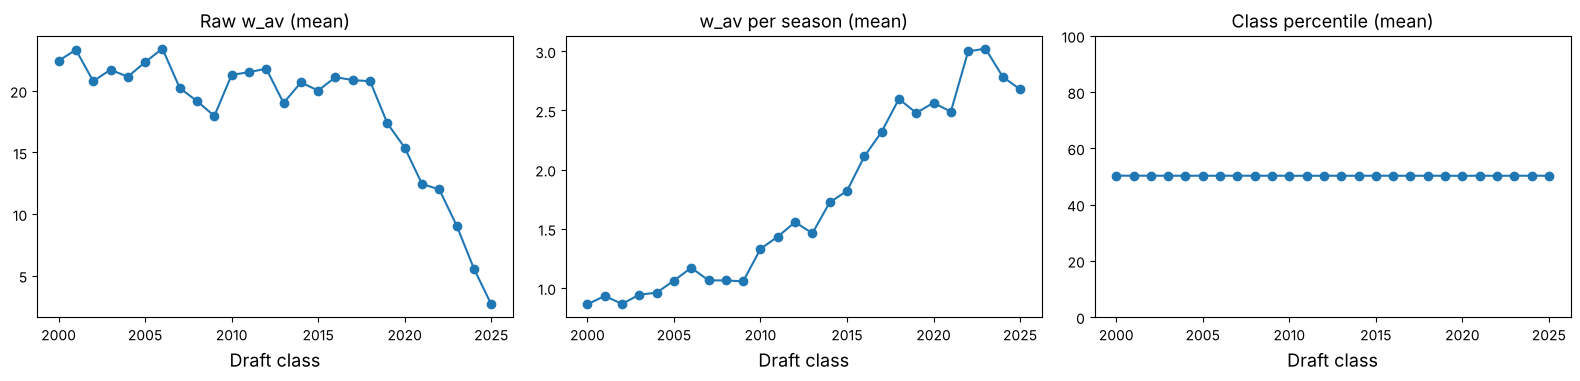

Modeling rows: 5098


pos_group
OL      837
WR      678
CB      634
LB      606
RB      482
DL      480
EDGE    456
S       394
TE      299
QB      232
Name: count, dtype: int64

In [5]:
# Percentile of w_av within each draft class (all drafted players, all positions)
df['wav_pct'] = df.groupby('draft_class')['w_av'].rank(pct=True) * 100
df['wav_per_season'] = df['w_av'] / (2025 - df['draft_class'] + 1)

by_class = df.groupby('draft_class')[['w_av', 'wav_per_season', 'wav_pct']].mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, by_class.columns,
                          ['Raw w_av (mean)', 'w_av per season (mean)', 'Class percentile (mean)']):
    ax.plot(by_class.index, by_class[col], 'o-')
    ax.set_title(title); ax.set_xlabel('Draft class')
axes[2].set_ylim(0, 100)
plt.tight_layout(); plt.show()

# Now drop K / P / LS
df = df[df['pos_group'].notna()].copy()
print('Modeling rows:', len(df))
df['pos_group'].value_counts()

### 2c. Skipped drills are left blank

Players skip drills for many reasons (injury, a top prospect protecting his stock, a player avoiding a drill he'd test poorly in). Because they **didn't participate**, we don't assume a result for them — no filling in a median, no guessed value. Their drill stays blank (`NaN`).

How the trees handle a blank, in plain terms: when a tree considers a split like *"forty ≤ 4.50?"*, the **cutoff is chosen using only the players who ran the forty**. Players without a forty are not given a time; they're simply carried down whichever side of that one split fits their outcome best, as their own group. Splits on drills they *did* do work normally for them.

For the cleanest possible read on each drill, Part 7c goes further and models each drill using **only** the players who completed it.

In [6]:
COMBINE = ['ht_in', 'wt', 'forty', 'bench', 'vertical', 'broad_jump', 'cone', 'shuttle']
DRAFT   = ['pick_num']
TARGET  = 'wav_pct'

print('Share of players who SKIPPED each drill:')
print(df[COMBINE].isna().mean().round(2).sort_values())

Share of players who SKIPPED each drill:
ht_in         0.00
wt            0.00
forty         0.08
vertical      0.22
broad_jump    0.23
bench         0.36
shuttle       0.39
cone          0.41
dtype: float64


## Part 3: Exploratory Data Analysis

How does each measurement relate to class-adjusted value at each position? We use **Spearman (rank) correlation**, which asks "do players who rank higher on this measure also rank higher in career value?" (−1 to +1; 0 = no relationship). Each cell uses only the players who did that drill.

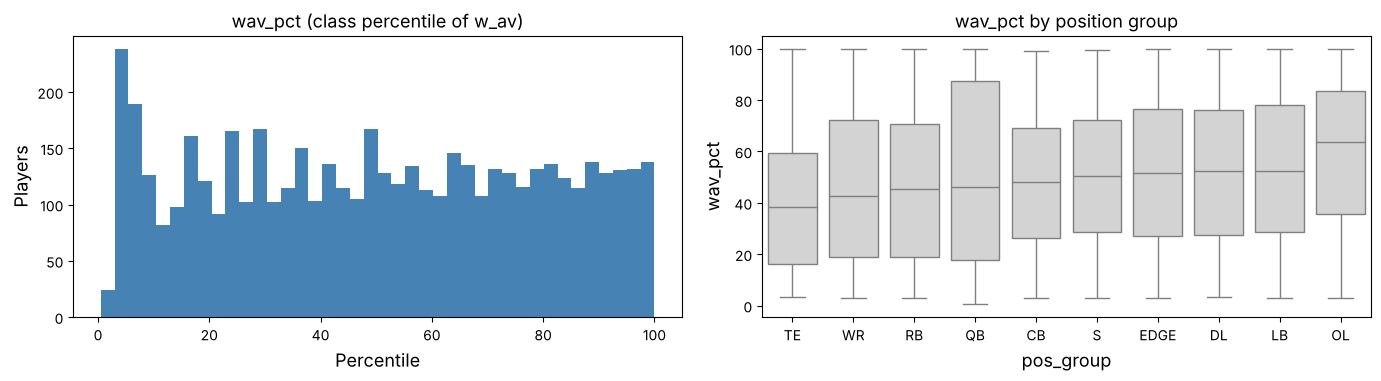

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df[TARGET], bins=40, color='steelblue')
axes[0].set_title('wav_pct (class percentile of w_av)'); axes[0].set_xlabel('Percentile'); axes[0].set_ylabel('Players')
order = df.groupby('pos_group')[TARGET].median().sort_values().index
sns.boxplot(data=df, x='pos_group', y=TARGET, order=order, ax=axes[1], color='lightgray')
axes[1].set_title('wav_pct by position group')
plt.tight_layout(); plt.show()

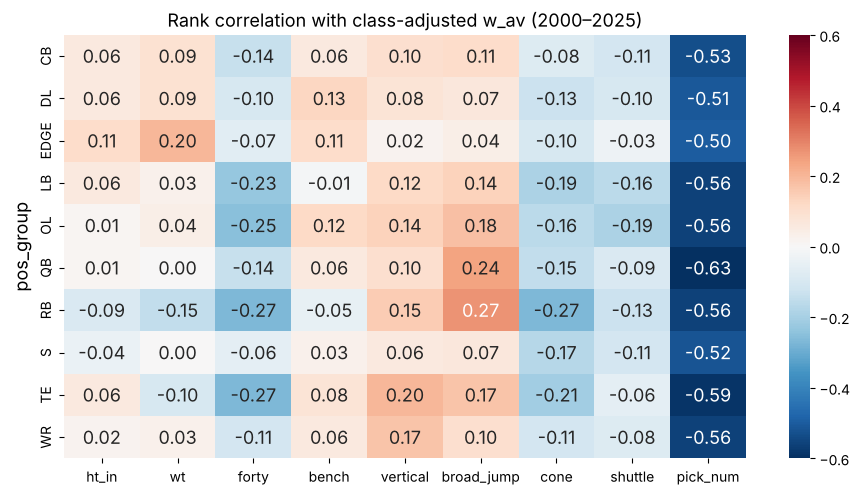

In [8]:
# Timed drills (forty, cone, shuttle): LOWER is better, so a negative value is "good".
corr = (df.groupby('pos_group')
          .apply(lambda g: g[COMBINE + DRAFT].corrwith(g[TARGET], method='spearman'))
          .round(2))
plt.figure(figsize=(11, 5.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, fmt='.2f')
plt.title('Rank correlation with class-adjusted w_av (2000–2025)')
plt.show()

**Reading the heatmap:** `pick_num` is strongly *negative* everywhere (drafted earlier → more career value). Most drill correlations are much weaker. That contrast previews the main result.

## Part 4: Train/Test Split

We hold out 20% of players as a **test set** the models never see during training or tuning, stratified by position so each position appears in both sets in the same proportion. For the all-positions models, position is added as one-hot (0/1) columns, since a 4.4 forty means something very different for a lineman than for a receiver.

In [9]:
pos_dummies = pd.get_dummies(df['pos_group'], prefix='pos', dtype=int)
POS_COLS = list(pos_dummies.columns)
data = pd.concat([df, pos_dummies], axis=1)

train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE,
                                     stratify=data['pos_group'])
y_train, y_test = train_df[TARGET], test_df[TARGET]
print('Train:', len(train_df), ' Test:', len(test_df))

def make_tree(**kw):
    return DecisionTreeRegressor(random_state=RANDOM_STATE, **kw)

def make_forest(**kw):
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **kw)

def rmse(y, p): return np.sqrt(mean_squared_error(y, p))

Train: 4078  Test: 1020


## Part 5: A Single Decision Tree on Combine Drills

### 5a. Look at a shallow tree

A regression tree asks a sequence of yes/no questions (e.g., "Is weight ≤ 260?") and predicts the **average `wav_pct`** of the training players who land in each leaf. We start at `max_depth=3` so it's readable.

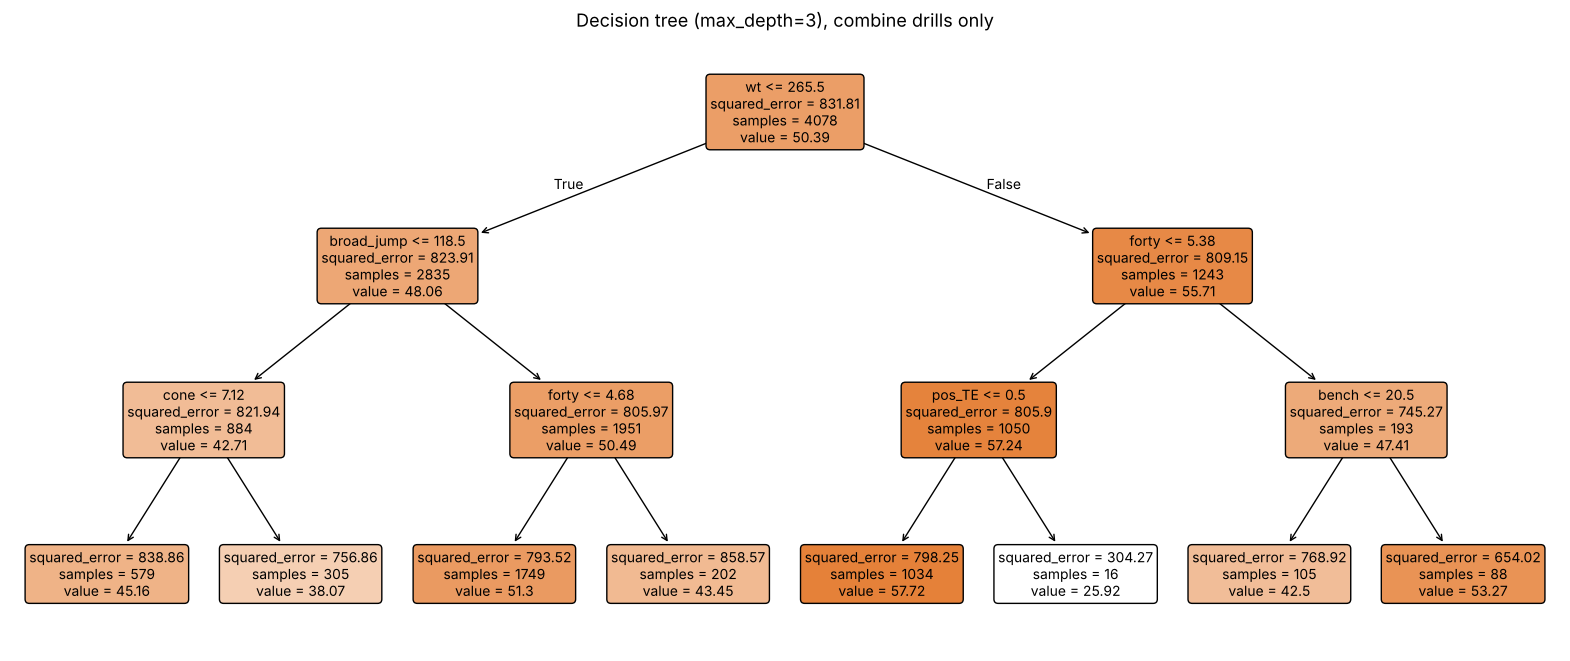

In [10]:
X_cols_A = COMBINE + POS_COLS        # combine only (+ position)
tree3 = make_tree(max_depth=3).fit(train_df[X_cols_A], y_train)

plt.figure(figsize=(20, 8))
plot_tree(tree3, feature_names=X_cols_A, filled=True, rounded=True, fontsize=10, precision=2)
plt.title('Decision tree (max_depth=3), combine drills only')
plt.show()

Each box shows the question, the **squared_error** (how spread-out `wav_pct` is in that box), how many players are there (`samples`), and the predicted percentile (`value`). The first questions asked are the splits that reduce error the most.

### 5b. Control overfitting with `max_depth`

**Metrics:** **R²** ("R-squared") is the share of the variation in the target the model explains: 1.0 = perfect, 0 = no better than predicting the average for everyone, negative = worse than that. **RMSE** is the typical size of a prediction error, here in percentile points.

,max_depth,train_R2,test_R2,test_RMSE
0,1,0.015,0.018,28.837
1,2,0.030,0.022,28.779
2,3,0.043,0.045,28.444
3,4,0.061,0.021,28.802
4,5,0.089,0.006,29.017
5,6,0.125,-0.025,29.466
6,8,0.226,-0.074,30.158
7,12,0.553,-0.352,33.845
8,None,0.997,-0.758,38.592


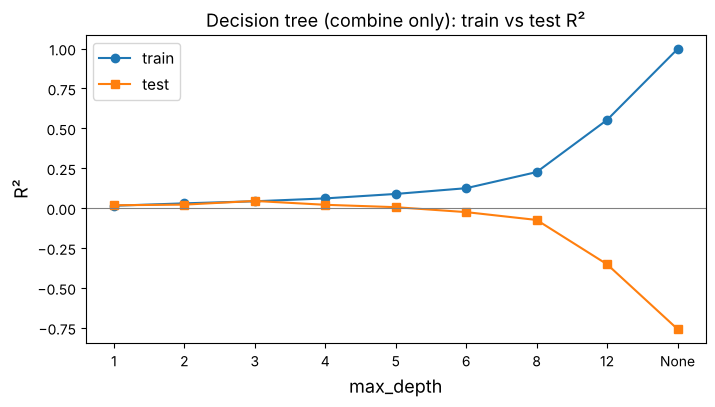

In [11]:
depths = [1, 2, 3, 4, 5, 6, 8, 12, None]
rows = []
for d in depths:
    m = make_tree(max_depth=d).fit(train_df[X_cols_A], y_train)
    rows.append({'max_depth': str(d),
                 'train_R2': r2_score(y_train, m.predict(train_df[X_cols_A])),
                 'test_R2':  r2_score(y_test,  m.predict(test_df[X_cols_A])),
                 'test_RMSE': rmse(y_test, m.predict(test_df[X_cols_A]))})
depth_tbl = pd.DataFrame(rows).round(3)
display(depth_tbl)

plt.figure(figsize=(8, 4))
plt.plot(depth_tbl['max_depth'], depth_tbl['train_R2'], 'o-', label='train')
plt.plot(depth_tbl['max_depth'], depth_tbl['test_R2'], 's-', label='test')
plt.axhline(0, color='gray', lw=0.8)
plt.xlabel('max_depth'); plt.ylabel('R²'); plt.title('Decision tree (combine only): train vs test R²')
plt.legend(); plt.show()

**What this shows:** train R² keeps climbing as the tree grows (it's memorizing individual players), while test R² peaks at a shallow depth and then falls — below zero for a fully grown tree. That widening gap is **overfitting**.

### 5c. Tune the tree with `GridSearchCV`

`GridSearchCV` tries every combination in a grid using **5-fold cross-validation** on the training set only: the training data is cut into 5 pieces, the model trains on 4 and is scored on the 5th, rotating 5 times. `min_samples_leaf` forces every leaf to hold at least that many players, and `ccp_alpha` prunes branches that don't reduce error enough — both are brakes on overfitting.

In [12]:
param_grid = {'max_depth': [3, 4, 5, 6, 8],
              'min_samples_leaf': [5, 10, 20, 40],
              'ccp_alpha': [0.0, 1.0, 5.0]}
grid_tree = GridSearchCV(make_tree(), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_tree.fit(train_df[X_cols_A], y_train)
best_tree = grid_tree.best_estimator_
print('Best params:', grid_tree.best_params_)
print(f'Best CV R²:  {grid_tree.best_score_:.3f}')
print(f'Test R²:     {r2_score(y_test, best_tree.predict(test_df[X_cols_A])):.3f}')
print(f'Test RMSE:   {rmse(y_test, best_tree.predict(test_df[X_cols_A])):.1f}')

Best params: {'ccp_alpha': 5.0, 'max_depth': 5, 'min_samples_leaf': 5}
Best CV R²:  0.010
Test R²:     0.023
Test RMSE:   28.8


### 5d. Decision trees have high variance

Refit a `max_depth=4` tree on six random 70% subsamples and print which feature it splits on **first** (the root) and where. If the root keeps moving, a single tree's "story" isn't stable — the motivation for random forests.

In [13]:
rng = np.random.RandomState(RANDOM_STATE)
for i in range(6):
    idx = rng.choice(len(train_df), size=int(0.7 * len(train_df)), replace=False)
    t = make_tree(max_depth=4).fit(train_df[X_cols_A].iloc[idx], y_train.iloc[idx])
    print(f'Sample {i+1}: root split on {X_cols_A[t.tree_.feature[0]]:<12} at {t.tree_.threshold[0]:.2f}')

Sample 1: root split on wt           at 293.50
Sample 2: root split on wt           at 265.50
Sample 3: root split on wt           at 265.50
Sample 4: root split on wt           at 271.50
Sample 5: root split on wt           at 270.50
Sample 6: root split on wt           at 258.50


## Part 6: Random Forest — Combine Only vs. Draft Only vs. Combine + Draft

A **random forest** builds hundreds of trees, each on a random bootstrap sample of players and considering a random subset of features at each split, then averages their predictions. Averaging cancels much of the single-tree instability.

Each feature set is tuned separately with `GridSearchCV`, so each one is shown at its best and the comparison is fair:
* **Combine only:** how much do drills alone explain?
* **Draft only:** how much does draft position alone explain?
* **Combine + Draft:** do drills add anything *on top of* where the player was drafted? If teams already "price in" the combine, this will barely beat draft only.

In [14]:
FEATURE_SETS = {'Combine only': COMBINE, 'Draft only': DRAFT, 'Combine + Draft': COMBINE + DRAFT}

# Each feature set gets its OWN tuned settings. This matters: a forest built on one feature
# (draft pick) overfits with tiny leaves, while a forest with 9 features may prefer them.
# Using one shared setting would make whichever set it suits best look artificially better.
rf_grid = {'max_depth': [4, 6, 8],
           'min_samples_leaf': [5, 10, 20, 40],
           'max_features': [0.6, 1.0]}
RF_PARAMS = {}
for name, cols in FEATURE_SETS.items():
    g = GridSearchCV(make_forest(n_estimators=200), rf_grid, cv=5, scoring='r2', n_jobs=-1)
    g.fit(train_df[cols + POS_COLS], y_train)
    RF_PARAMS[name] = g.best_params_
    print(f'{name:<16} best params: {g.best_params_}  (CV R² = {g.best_score_:.3f})')

Combine only     best params: {'max_depth': 6, 'max_features': 1.0, 'min_samples_leaf': 20}  (CV R² = 0.044)


Draft only       best params: {'max_depth': 6, 'max_features': 0.6, 'min_samples_leaf': 40}  (CV R² = 0.321)


Combine + Draft  best params: {'max_depth': 8, 'max_features': 0.6, 'min_samples_leaf': 40}  (CV R² = 0.320)


In [15]:
def overall_table(train, test):
    out = []
    for name, cols in FEATURE_SETS.items():
        X_cols = cols + POS_COLS
        rf = make_forest(n_estimators=300, **RF_PARAMS[name])
        cv = cross_val_score(rf, train[X_cols], train[TARGET], cv=5, scoring='r2', n_jobs=-1)
        rf.fit(train[X_cols], train[TARGET])
        pred = rf.predict(test[X_cols])
        out.append({'Features': name, 'CV_R2_mean': cv.mean(), 'CV_R2_sd': cv.std(),
                    'Test_R2': r2_score(test[TARGET], pred), 'Test_RMSE': rmse(test[TARGET], pred),
                    'Test_MAE': mean_absolute_error(test[TARGET], pred)})
    return pd.DataFrame(out).round(3)

overall = overall_table(train_df, test_df)
display(overall)

,Features,CV_R2_mean,CV_R2_sd,Test_R2,Test_RMSE,Test_MAE
0,Combine only,0.045,0.011,0.078,27.950,24.065
1,Draft only,0.321,0.037,0.322,23.962,19.862
2,Combine + Draft,0.321,0.035,0.324,23.939,19.777


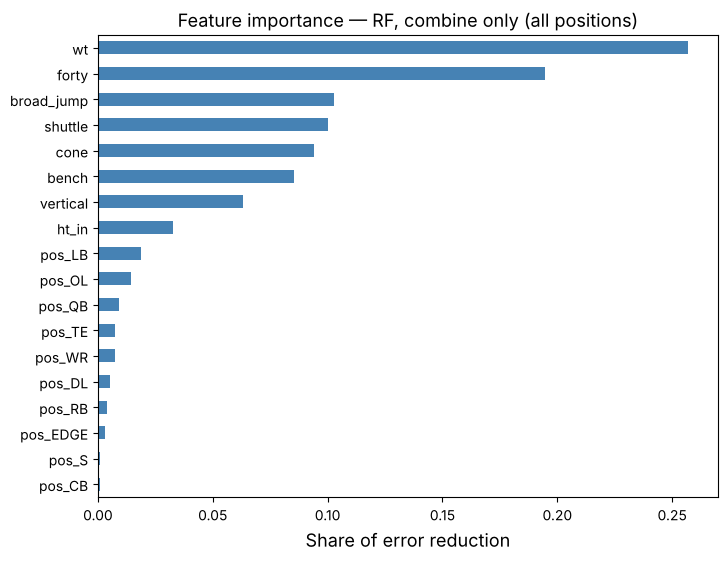

In [16]:
# Built-in (impurity) feature importance of the combine-only forest: how much each feature
# reduced prediction error across all the splits that used it, scaled to sum to 1.
X_cols = COMBINE + POS_COLS
rf_A = make_forest(n_estimators=300, **RF_PARAMS['Combine only']).fit(train_df[X_cols], y_train)
imp = pd.Series(rf_A.feature_importances_, index=X_cols).sort_values()
plt.figure(figsize=(8, 6))
imp.plot.barh(color='steelblue')
plt.title('Feature importance — RF, combine only (all positions)')
plt.xlabel('Share of error reduction'); plt.show()

## Part 7: Models by Position

### 7a. Three feature sets at each position

For each position group we run **5-fold cross-validation** on all of that position's players (a separate fixed test set would be too small at some positions). Each feature set uses its tuned settings from Part 6, and because positions have very different sample sizes, we also let each feature set pick its best minimum leaf size (5, 20, or 40 players) at each position. Every feature set gets the same chance, so no set looks better just because the settings happened to suit it. A tuned-down single tree on combine drills is included for reference. Position dummies aren't needed inside a single-position model.

In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
POSITIONS = df['pos_group'].value_counts().index.tolist()
LEAF_GRID = [5, 20, 40]

def position_table(frame):
    rows = []
    for pos in POSITIONS:
        sub = frame[frame['pos_group'] == pos]
        y = sub[TARGET]
        tr = cross_validate(make_tree(max_depth=4, min_samples_leaf=20), sub[COMBINE], y, cv=kf,
                            scoring=('r2', 'neg_root_mean_squared_error'))
        rows.append({'pos': pos, 'n': len(sub), 'model': 'Tree', 'features': 'Combine only',
                     'R2': tr['test_r2'].mean(), 'RMSE': -tr['test_neg_root_mean_squared_error'].mean()})
        for name, cols in FEATURE_SETS.items():
            # Same small leaf-size grid for every feature set; keep each set's best CV R².
            best = None
            for leaf in LEAF_GRID:
                params = {**RF_PARAMS[name], 'min_samples_leaf': leaf}
                res = cross_validate(make_forest(n_estimators=200, **params), sub[cols], y, cv=kf,
                                     scoring=('r2', 'neg_root_mean_squared_error'), n_jobs=-1)
                if best is None or res['test_r2'].mean() > best['test_r2'].mean():
                    best, best_leaf = res, leaf
            rows.append({'pos': pos, 'n': len(sub), 'model': 'Random Forest', 'features': name,
                         'R2': best['test_r2'].mean(), 'RMSE': -best['test_neg_root_mean_squared_error'].mean(),
                         'leaf': best_leaf})
    return pd.DataFrame(rows)

def summarize(pos_res):
    s = (pos_res.assign(label=pos_res['model'].str.replace('Random Forest', 'RF') + ': ' + pos_res['features'])
                .pivot_table(index=['pos', 'n'], columns='label', values='R2')
                .sort_values('RF: Combine only', ascending=False))
    s['Drills add over draft'] = s['RF: Combine + Draft'] - s['RF: Draft only']
    return s.round(3)

pos_res = position_table(df)
summary = summarize(pos_res)
display(summary)

,label,RF: Combine + Draft,RF: Combine only,RF: Draft only,Tree: Combine only,Drills add over draft
pos,n,,,,,
RB,482,0.325,0.092,0.299,-0.028,0.026
OL,837,0.318,0.061,0.309,-0.042,0.010
QB,232,0.380,0.021,0.432,-0.124,-0.052
LB,606,0.298,0.019,0.300,-0.072,-0.002
EDGE,456,0.227,0.017,0.229,-0.016,-0.001
TE,299,0.324,0.007,0.328,-0.067,-0.004
CB,634,0.285,0.005,0.287,-0.099,-0.001
WR,678,0.295,-0.003,0.291,-0.063,0.004
S,394,0.253,-0.006,0.241,-0.055,0.012


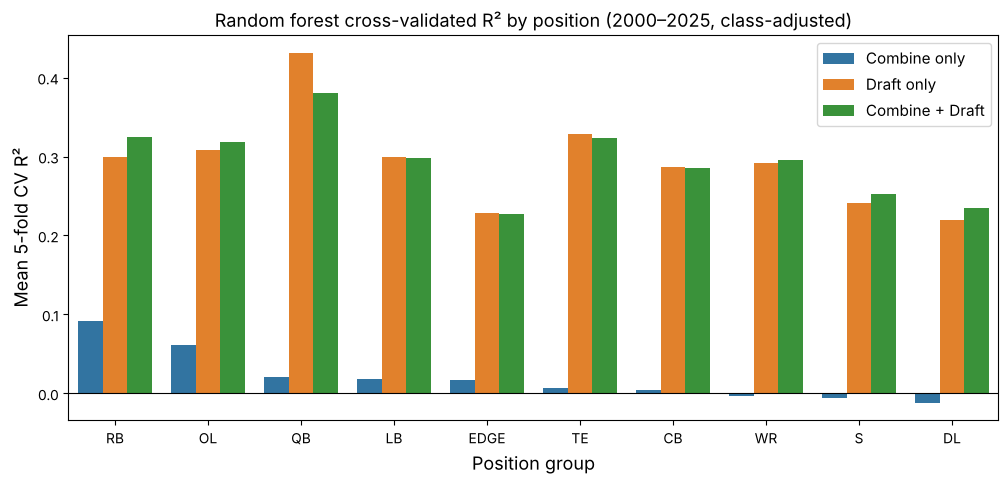

In [18]:
rf_only = pos_res[pos_res['model'] == 'Random Forest']
order = summary.index.get_level_values('pos')
plt.figure(figsize=(12, 5))
sns.barplot(data=rf_only, x='pos', y='R2', hue='features', order=order,
            hue_order=['Combine only', 'Draft only', 'Combine + Draft'])
plt.axhline(0, color='black', lw=0.8)
plt.title('Random forest cross-validated R² by position (2000–2025, class-adjusted)')
plt.ylabel('Mean 5-fold CV R²'); plt.xlabel('Position group'); plt.legend(title='')
plt.show()

**How to read this:** the **Combine only** bar answers the project question directly. The gap between **Draft only** and **Combine + Draft** shows whether drills add anything once you know where the player was drafted — near zero means the drill information is already reflected in draft position.

### 7b. Which features does each position's forest lean on?

Built-in importance from the combine-only forest fit on all of each position's players. This shows where the model *looks*; 7c below measures how much each drill actually predicts.

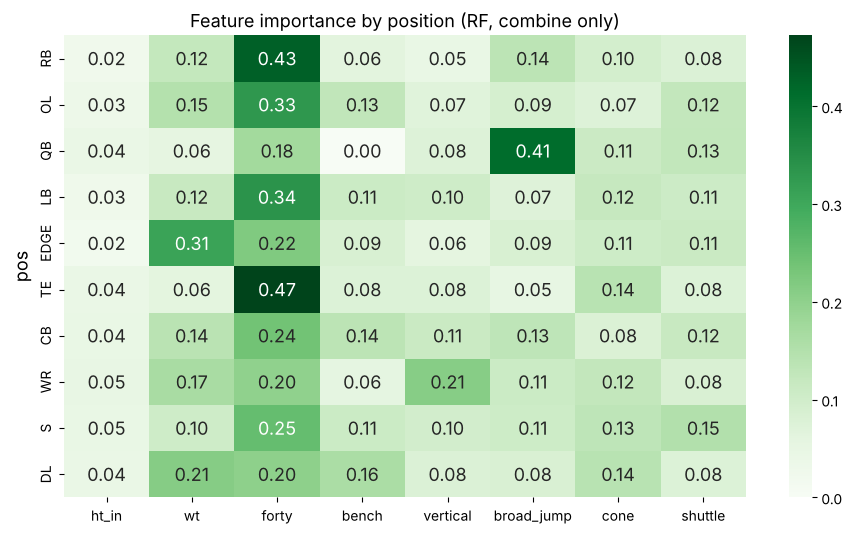

In [19]:
imp_rows = {}
for pos in POSITIONS:
    sub = df[df['pos_group'] == pos]
    m = make_forest(n_estimators=300, **RF_PARAMS['Combine only']).fit(sub[COMBINE], sub[TARGET])
    imp_rows[pos] = m.feature_importances_
pos_imp = pd.DataFrame(imp_rows, index=COMBINE).T.loc[order]
plt.figure(figsize=(11, 6))
sns.heatmap(pos_imp, annot=True, fmt='.2f', cmap='Greens')
plt.title('Feature importance by position (RF, combine only)')
plt.show()

### 7c. Drill by drill, using only players who completed the drill

This is the strictest version of "don't assume anything about skipped drills." For every position × drill, we keep **only the players who did that drill**, fit a shallow random forest using **that one drill** (each tree only 2 questions deep, with at least 40 players per leaf, so it learns a few clear steps rather than chasing noise), and measure 5-fold cross-validated R². So the WR forty number answers: *"Among receivers who ran the forty, how much of their class-adjusted career value does the forty alone explain?"*

Cells with fewer than 60 players who did the drill are left blank (too few to trust).

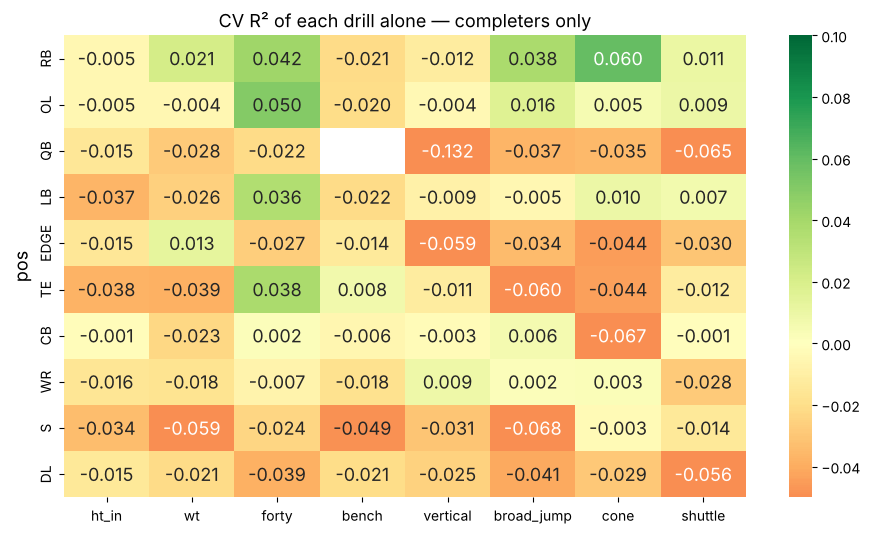

Players who completed each drill:


,ht_in,wt,forty,bench,vertical,broad_jump,cone,shuttle
pos,,,,,,,,
RB,480,481,454,335,401,391,259,266
OL,836,836,764,589,659,652,580,598
QB,232,232,196,6,167,166,152,153
LB,605,605,559,442,473,477,357,366
EDGE,456,456,412,316,355,351,262,270
TE,299,299,269,214,230,222,187,192
CB,632,632,599,446,499,498,345,361
WR,676,676,642,295,543,527,376,388
S,390,390,356,294,312,309,208,207


In [20]:
MIN_N = 60
single_r2, single_n = {}, {}
for pos in POSITIONS:
    sub = df[df['pos_group'] == pos]
    single_r2[pos], single_n[pos] = {}, {}
    for drill in COMBINE:
        done = sub[sub[drill].notna()]                 # only players who did this drill
        single_n[pos][drill] = len(done)
        if len(done) < MIN_N:
            single_r2[pos][drill] = np.nan
            continue
        m = make_forest(n_estimators=200, max_depth=2, min_samples_leaf=40)
        single_r2[pos][drill] = cross_val_score(m, done[[drill]], done[TARGET], cv=kf, scoring='r2').mean()
single_r2 = pd.DataFrame(single_r2).T.loc[order, COMBINE]
single_n = pd.DataFrame(single_n).T.loc[order, COMBINE]

plt.figure(figsize=(11, 6))
sns.heatmap(single_r2, annot=True, fmt='.3f', cmap='RdYlGn', center=0, vmin=-0.05, vmax=0.10)
plt.title('CV R² of each drill alone — completers only')
plt.show()
print('Players who completed each drill:')
display(single_n)

In [21]:
for pos in single_r2.index:
    top = single_r2.loc[pos].dropna().sort_values(ascending=False).head(3)
    print(f"{pos:<5} " + ', '.join(f"{k} ({v:.3f})" for k, v in top.items()))

RB    cone (0.060), forty (0.042), broad_jump (0.038)
OL    forty (0.050), broad_jump (0.016), shuttle (0.009)
QB    ht_in (-0.015), forty (-0.022), wt (-0.028)
LB    forty (0.036), cone (0.010), shuttle (0.007)
EDGE  wt (0.013), bench (-0.014), ht_in (-0.015)
TE    forty (0.038), bench (0.008), vertical (-0.011)
CB    broad_jump (0.006), forty (0.002), shuttle (-0.001)
WR    vertical (0.009), cone (0.003), broad_jump (0.002)
S     cone (-0.003), shuttle (-0.014), forty (-0.024)
DL    ht_in (-0.015), bench (-0.021), wt (-0.021)


### 7d. Thresholds or rankings? What a "good" number looks like

For the best single drill at several positions (from 7c), we plot the single-drill forest's predicted percentile across the range of that drill — again using only players who did it. A flat line means the drill doesn't move the prediction. A **step** means a threshold ("under X is fine, over X is a red flag"), which speaks to our proposal's threshold-vs-ranking question. Tick marks along the bottom show where the middle 80% of players fall.

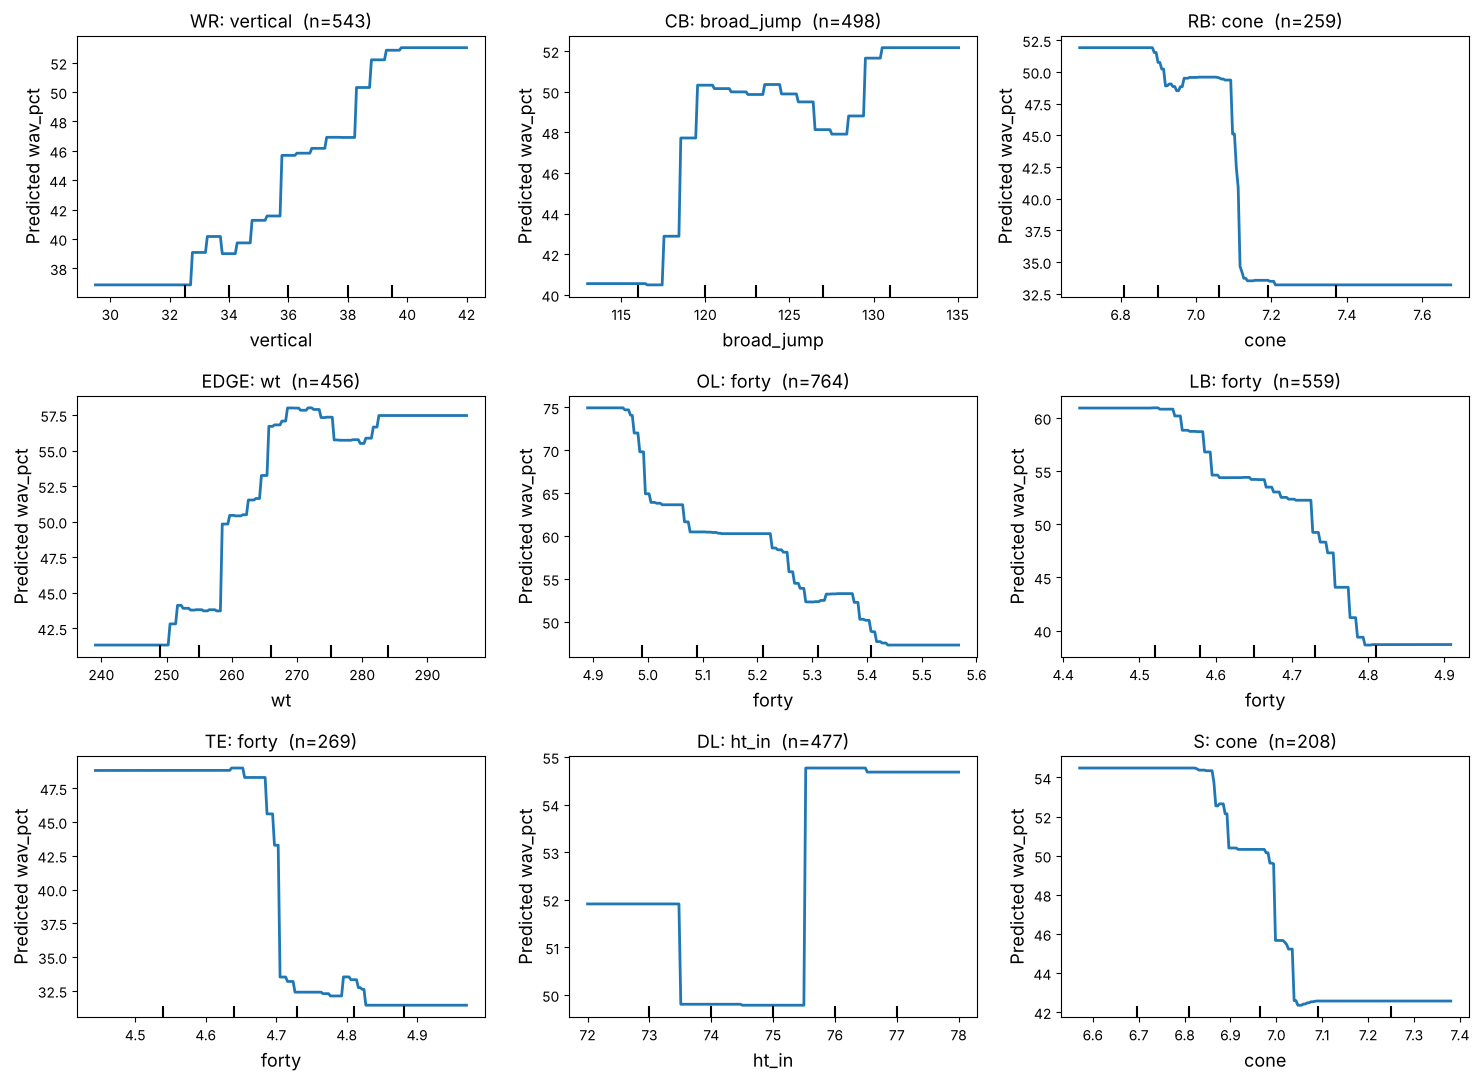

In [22]:
show = [p for p in ['WR', 'CB', 'RB', 'EDGE', 'OL', 'LB', 'TE', 'DL', 'S'] if p in single_r2.index]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, pos in zip(axes.ravel(), show):
    drill = single_r2.loc[pos].idxmax()
    done = df[(df['pos_group'] == pos) & df[drill].notna()]
    m = make_forest(n_estimators=200, max_depth=2, min_samples_leaf=40).fit(done[[drill]], done[TARGET])
    lo, hi = done[drill].quantile([0.02, 0.98])
    grid = np.linspace(lo, hi, 200)
    ax.plot(grid, m.predict(pd.DataFrame({drill: grid})), lw=2)
    for q in done[drill].quantile([0.1, 0.25, 0.5, 0.75, 0.9]):
        ax.axvline(q, ymin=0, ymax=0.04, color='black')
    ax.set_title(f'{pos}: {drill}  (n={len(done)})'); ax.set_xlabel(drill); ax.set_ylabel('Predicted wav_pct')
plt.tight_layout(); plt.show()

## Part 8: Robustness Check — Mature Classes Only

For recent classes, the class percentile is based on only a few seasons, which largely reflects early playing time (and teams give early snaps to high picks). If that were driving our results, we'd expect the conclusions to change when we use only classes whose careers are mostly complete. Here we re-run the position comparison on **2000–2019 only** and put it next to the full 2000–2025 results.

In [23]:
mature = df[df['draft_class'] <= 2019]
print('Mature-class rows:', len(mature))
summary_mature = summarize(position_table(mature))

cols = ['RF: Combine only', 'RF: Draft only', 'Drills add over draft']
compare = pd.concat({'2000–2025': summary.droplevel('n')[cols],
                     '2000–2019': summary_mature.droplevel('n')[cols]}, axis=1)
display(compare.round(3))

Mature-class rows: 3893


2000–2025                                             2000–2019  \
label RF: Combine only RF: Draft only Drills add over draft RF: Combine only   
pos                                                                            
RB               0.092          0.299                 0.026            0.120   
OL               0.061          0.309                 0.010            0.025   
QB               0.021          0.432                -0.052           -0.016   
LB               0.019          0.300                -0.002            0.008   
EDGE             0.017          0.229                -0.001            0.029   
TE               0.007          0.328                -0.004            0.089   
CB               0.005          0.287                -0.001            0.008   
WR              -0.003          0.291                 0.004            0.006   
S               -0.006          0.241                 0.012           -0.031   
DL              -0.012          0.219                 0.015            0.011   

                                            
label RF: Draft only Drills add over draft  
pos                                         
RB             0.333                 0.016  
OL             0.278                -0.002  
QB             0.380                -0.042  
LB             0.268                 0.001  
EDGE           0.226                -0.013  
TE             0.308                 0.008  
CB             0.277                -0.001  
WR             0.276                 0.001  
S              0.268                -0.012  
DL             0.188                 0.011

## Part 9: Results and Interpretation

*Numbers below are from our run: 5,098 drafted players from the 2000–2025 classes (excluding K/P/LS). Colab may show slightly different decimals depending on its scikit-learn version, but the pattern holds.*

**Reminder of the target:** `wav_pct` is a player's percentile in career `w_av` among his own draft class (50 = middle of his class). Using it puts a 2024 draftee and a 2004 draftee on equal footing.

### 1. On their own, combine drills explain very little of career value
* The **best single decision tree** on combine drills explained about **1–2%** of the variation in class-adjusted value (CV R² 0.010, test R² 0.023). Fully grown trees went strongly negative on the test set: they memorized the training players.
* The **random forest** did a bit better: **CV R² 0.045, test R² 0.078**. It's typically off by ~24 percentile points, against ~25 when you just guess the average for everyone.
* Weight was the root split in all six subsamples, but its cutoff moved between ~258 and ~294 lbs, so a single tree's exact rules aren't stable.

### 2. Draft position carries almost all of the predictable signal, and drills add nothing on top of it
| Random forest, all positions (each feature set tuned separately) | CV R² | Test R² | Test RMSE |
|---|---|---|---|
| Combine only | 0.045 | 0.078 | 28.0 |
| Draft only | 0.321 | 0.322 | 24.0 |
| Combine + Draft | 0.321 | 0.324 | 23.9 |

Once a model knows where a player was drafted, adding his drills changes almost nothing. The most likely reason: teams already use the combine (plus film, interviews and medicals) when they draft, so whatever the drills say is already reflected in the pick.

*Method note:* in an earlier version, every feature set shared one set of forest settings. That made the draft-only model (one feature) overfit and look worse, so drills appeared to add 3–7 points. Tuning each set separately removed that artifact.

### 3. By position: drills say the most for RB and OL, and essentially nothing for DL, S, WR, or QB
Random forest, 5-fold CV R² (2000–2025, class-adjusted):

| Position | n | Combine only | Draft only | Combine + Draft | Drills add over draft |
|---|---|---|---|---|---|
| RB | 482 | **0.092** | 0.299 | 0.325 | +0.03 |
| OL | 837 | **0.061** | 0.309 | 0.318 | +0.01 |
| QB | 232 | 0.021 | 0.432 | 0.380 | −0.05 |
| LB | 606 | 0.019 | 0.300 | 0.298 | 0.00 |
| EDGE | 456 | 0.017 | 0.229 | 0.227 | 0.00 |
| TE | 299 | 0.007 | 0.328 | 0.324 | 0.00 |
| CB | 634 | 0.005 | 0.287 | 0.285 | 0.00 |
| WR | 678 | −0.003 | 0.291 | 0.295 | 0.00 |
| S | 394 | −0.006 | 0.241 | 0.253 | +0.01 |
| DL | 480 | −0.012 | 0.219 | 0.234 | +0.02 |

* Even at the best position (RB), the drills explain under 10% of career value.
* The only possible gain from drills on top of the draft is at **RB (+0.03)**, and that's small enough to be noise. For QB, adding the drills actually *hurts*: they're pure noise there.

### 4. Drill by drill, using only players who completed each drill (Part 7c)
* **RB:** 3-cone (R² 0.060), forty (0.042), broad jump (0.038). Running back is the one position where several drills each carry some signal.
* **OL:** forty (0.050). Nothing else matters much.
* **TE:** forty (0.038).
* **LB:** forty (0.036).
* **EDGE:** weight (0.013), which is more about size than athletic testing.
* **WR, CB:** best drills are around 0.01 (vertical for WR, broad jump for CB), which is effectively nothing.
* **S, DL, QB:** no drill beats guessing the average.
* **Bench press** is never useful at any position.

### 5. Thresholds or rankings? (Part 7d)
The shape of each curve answers our proposal's threshold-vs-ranking question:
* **Threshold ("clear the bar") positions:**
  * **RB 3-cone:** predicted percentile falls from ~50 to ~33 once the cone is slower than about **7.1 seconds**, then stays flat.
  * **TE forty:** falls from ~48 to ~32 at about **4.70**; faster than that, more speed adds little.
  * **EDGE weight:** rises from ~42 to ~57 between about **250 and 270 lbs**, then levels off.
* **Ranking ("faster is always better") positions:**
  * **OL forty:** declines steadily from ~4.95 (75th percentile predicted) to ~5.45 (47th).
  * **LB forty:** declines steadily from ~4.55 (61st) to ~4.80 (39th).
* At positions where the drill's R² is near or below zero (WR, CB, S, DL), the curve's shape is too weak to act on.

These are associations, not causes, and each step is learned from a few hundred players, so treat the exact cutoffs as rough.

### 6. Robustness check: mature classes only (Part 8)
Re-running on 2000–2019 only, where careers are mostly complete:
* The headline holds. Drills alone are still weak everywhere, and adding them to draft position still adds about zero at every position (−0.04 to +0.02).
* **RB stays on top** (combine-only R² 0.120).
* **TE rises to 0.089** (from 0.007 with all classes). Among TEs from the 2000–2019 classes, faster forty times and higher verticals line up with more career value (rank correlations of about −0.32 and +0.26). Among the 72 TEs drafted 2020–2025, those relationships are close to zero. Two explanations fit, and this data can't tell them apart: (1) a recent TE's percentile reflects only 1–5 seasons, and TEs often take years to become full-time players, so early rankings may not match where their careers end up; or (2) the link between TE athleticism and value has weakened in recent years. With only 72 recent TEs, chance is also a real possibility. Treat the TE result as a lead worth checking, not a finding.
* **OL drops to 0.025** (from 0.061), so the OL signal is partly an early-career effect.

### Bottom line
Combine drills are a **weak predictor of career value**: about 5% of class-adjusted value explained overall, and at most 9–12% (RB). **Once draft position is known, they add essentially nothing**, which suggests NFL teams already account for them. The value that does exist is position-specific. **Agility and speed matter for RBs, straight-line speed matters for OL, TE and LB, size matters for EDGE, and nothing at the combine predicts success for QB, S or DL.**

### Limitations
* Only drafted players have `w_av` in this data, so undrafted players (often the weakest testers) are missing. That probably *understates* how much drills matter across all prospects.
* The class percentile removes career length, but for 2023–2025 draftees it still reflects only 1–3 seasons, which mostly captures early playing time, and teams give early playing time to high picks. Part 8 shows the conclusions hold without those classes.
* A percentile records rank, not size: the gap between the 99th and 95th percentile might be 80 `w_av` points or 15.
* Skipped drills are left blank. The multi-drill models still carry blank-drill players down a branch as their own group, while the drill-by-drill models (7c, 7d) leave them out entirely. Players who skip may differ systematically from those who test (for example, top prospects skipping the bench), so each drill's results describe **players who did that drill**.
